# PROJECT-3 EDA + Feature engineering

## 0. Предварительное знакомство с данными.

### 0.1 Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

print(pd.__version__)
print(np.__version__)

2.3.3
2.3.5


### 0.2 Загрузка данных

In [2]:
hotels = pd.read_csv('data/hotels.csv', skipinitialspace=True)
display(hotels.head())
display(hotels.info())

,hotel_address,additional_number_of_scoring,review_date,average_score,hotel_name,reviewer_nationality,negative_review,review_total_negative_word_counts,total_number_of_reviews,positive_review,review_total_positive_word_counts,total_number_of_reviews_reviewer_has_given,reviewer_score,tags,days_since_review,lat,lng
0,Stratton Street Mayfair Westminster Borough Lo...,581,2/19/2016,8.4,The May Fair Hotel,United Kingdom,Leaving,3,1994,Staff were amazing,4,7,10.0,"[' Leisure trip ', ' Couple ', ' Studio Suite ...",531 day,51.507894,-0.143671
1,130 134 Southampton Row Camden London WC1B 5AF...,299,1/12/2017,8.3,Mercure London Bloomsbury Hotel,United Kingdom,poor breakfast,3,1361,location,2,14,6.3,"[' Business trip ', ' Couple ', ' Standard Dou...",203 day,51.521009,-0.123097
2,151 bis Rue de Rennes 6th arr 75006 Paris France,32,10/18/2016,8.9,Legend Saint Germain by Elegancia,China,No kettle in room,6,406,No Positive,0,14,7.5,"[' Leisure trip ', ' Solo traveler ', ' Modern...",289 day,48.845377,2.325643
3,216 Avenue Jean Jaures 19th arr 75019 Paris Fr...,34,9/22/2015,7.5,Mercure Paris 19 Philharmonie La Villette,United Kingdom,No Negative,0,607,Friendly staff quiet comfortable room spotless...,11,8,10.0,"[' Leisure trip ', ' Solo traveler ', ' Standa...",681 day,48.888697,2.394540
4,Molenwerf 1 1014 AG Amsterdam Netherlands,914,3/5/2016,8.5,Golden Tulip Amsterdam West,Poland,Torn sheets,4,7586,The staff was very friendly and helpful Breakf...,20,10,9.6,"[' Business trip ', ' Couple ', ' Standard Dou...",516 day,52.385601,4.847060


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 386803 entries, 0 to 386802
Data columns (total 17 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   hotel_address                               386803 non-null  object 
 1   additional_number_of_scoring                386803 non-null  int64  
 2   review_date                                 386803 non-null  object 
 3   average_score                               386803 non-null  float64
 4   hotel_name                                  386803 non-null  object 
 5   reviewer_nationality                        386408 non-null  object 
 6   negative_review                             385351 non-null  object 
 7   review_total_negative_word_counts           386803 non-null  int64  
 8   total_number_of_reviews                     386803 non-null  int64  
 9   positive_review                             386647 non-null  object 
 

None

## 1. Очистка данных от пропущенных значений.
 Заполняем недостающие значения нулями

In [3]:
hotels['lat'] = hotels['lat'].fillna(0)
hotels['lng'] = hotels['lng'].fillna(0)
hotels['reviewer_nationality'] = hotels['reviewer_nationality'].fillna(0)
hotels['negative_review'] = hotels['negative_review'].fillna(0)
hotels['positive_review'] = hotels['positive_review'].fillna(0)

display(hotels.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 386803 entries, 0 to 386802
Data columns (total 17 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   hotel_address                               386803 non-null  object 
 1   additional_number_of_scoring                386803 non-null  int64  
 2   review_date                                 386803 non-null  object 
 3   average_score                               386803 non-null  float64
 4   hotel_name                                  386803 non-null  object 
 5   reviewer_nationality                        386803 non-null  object 
 6   negative_review                             386803 non-null  object 
 7   review_total_negative_word_counts           386803 non-null  int64  
 8   total_number_of_reviews                     386803 non-null  int64  
 9   positive_review                             386803 non-null  object 
 

None

На этапе заполнения недостающих значений, я выбрал заполнить их нулями, как самый простой вариант. Из негативных моментов, я потерял некоторое количество геоданных, однако признаки города и страны и получу позже из адресов.

## 2. Создание новых признаков.

### 2.1 Получение название города/страны из признака адрес отеля. 


In [4]:
# извлечение страны 
hotels['country'] = (
    hotels['hotel_address']
    .str.strip()                     # убираем пробелы по краям
    .str.split(',')                  # запятые
    .str[-1]                         # берём последний фрагмент
    .str.strip()
    .str.split()                     # разбиваем по пробелам
    .str[-1] 
)

# список известных городов
known_cities = ['London' 'Paris' 'Amsterdam' 'Milan' 'Vienna' 'Barcelona']

def extract_city(address: str) -> str:
    if pd.isna(address):
        return np.nan
    for city in known_cities:
        # \b — граница слова
        if pd.Series([address]).str.contains(rf'\b{city}\b', regex=True).iloc[0]:
            return city
    #если город не из списка — берём токен перед страной
    parts = address.strip().split()
    return parts[-2] if len(parts) >= 2 else np.nan

hotels['city'] = hotels['hotel_address'].apply(extract_city)

# проверка результата
print("Уникальные страны:", hotels['country'].unique())
print("Уникальные города:", hotels['city'].unique())

Уникальные страны: ['Kingdom' 'France' 'Netherlands' 'Italy' 'Austria' 'Spain']
Уникальные города: ['United' 'Paris' 'Amsterdam' 'Milan' 'Vienna' 'Barcelona']


## 2.2 Анализ даты оставления отзыва. 
Создание новых признаков на основе даты.

In [5]:
# review_date в формате M/D/YYYY (например, "2/19/2016")
hotels['review_date'] = pd.to_datetime(hotels['review_date'], format='%m/%d/%Y')

# проверяем, что распозналось корректно
print(hotels['review_date'].min(), hotels['review_date'].max())
print(hotels['review_date'].dtype)

2015-08-04 00:00:00 2017-08-03 00:00:00
datetime64[ns]


In [6]:
d = hotels['review_date']

# календарные признаки
hotels['review_year'] = d.dt.year
hotels['review_month'] = d.dt.month
hotels['review_day'] = d.dt.day
hotels['review_quarter'] = d.dt.quarter
hotels['review_dayofweek'] = d.dt.dayofweek
hotels['review_day_name'] = d.dt.day_name()
hotels['review_week'] = d.dt.isocalendar().week.astype(int)
hotels['review_dayofyear'] = d.dt.dayofyear

# выходные
hotels['review_is_weekend'] = hotels['review_dayofweek'].isin([5, 6]).astype(int)

# месяц
hotels['review_month_name'] = d.dt.month_name()

display(hotels.head())

,hotel_address,additional_number_of_scoring,review_date,average_score,hotel_name,reviewer_nationality,negative_review,review_total_negative_word_counts,total_number_of_reviews,positive_review,...,review_year,review_month,review_day,review_quarter,review_dayofweek,review_day_name,review_week,review_dayofyear,review_is_weekend,review_month_name
0,Stratton Street Mayfair Westminster Borough Lo...,581,2016-02-19,8.4,The May Fair Hotel,United Kingdom,Leaving,3,1994,Staff were amazing,...,2016,2,19,1,4,Friday,7,50,0,February
1,130 134 Southampton Row Camden London WC1B 5AF...,299,2017-01-12,8.3,Mercure London Bloomsbury Hotel,United Kingdom,poor breakfast,3,1361,location,...,2017,1,12,1,3,Thursday,2,12,0,January
2,151 bis Rue de Rennes 6th arr 75006 Paris France,32,2016-10-18,8.9,Legend Saint Germain by Elegancia,China,No kettle in room,6,406,No Positive,...,2016,10,18,4,1,Tuesday,42,292,0,October
3,216 Avenue Jean Jaures 19th arr 75019 Paris Fr...,34,2015-09-22,7.5,Mercure Paris 19 Philharmonie La Villette,United Kingdom,No Negative,0,607,Friendly staff quiet comfortable room spotless...,...,2015,9,22,3,1,Tuesday,39,265,0,September
4,Molenwerf 1 1014 AG Amsterdam Netherlands,914,2016-03-05,8.5,Golden Tulip Amsterdam West,Poland,Torn sheets,4,7586,The staff was very friendly and helpful Breakf...,...,2016,3,5,1,5,Saturday,9,65,1,March


## 2.3 Теги (tags). 
Нужно выполнить анализ данных. Создать на его основе несколько новых признаков (достаточно 2-3).

In [7]:
# парсим строку в список
def parse_tags(s):
    # если список уже есть, просто возвращаем его
    if isinstance(s, list):
        return s
    # если это не строка, возвращаем пустой список
    if not isinstance(s, str):
        return []
    
    s = s.strip().strip('"').strip("'")
    s = s.replace('[', '').replace(']', '')
    result = []
    for part in s.split(','):
        part = part.strip().strip('"').strip("'").strip()
        if part:
            result.append(part)
    return result

hotels['tags'] = hotels['tags'].apply(parse_tags)

# извлекаем признаки
trip_type = {'Leisure trip', 'Business trip'}
traveler_type = {'Solo traveler', 'Couple', 'Group', 'Family with young children', 'Family with older children'}
service_tags = {'No Positive', 'No Negative'}

def extract_tag(tags, valid_set):
    for tag in tags:
        if tag in valid_set:
            return tag
    return np.nan

def extract_room_type(tags):
    for tag in tags:
        if tag in trip_type or tag in traveler_type or tag in service_tags:
            continue
        if tag.startswith('Stayed ') or tag.startswith('Submitted from'):
            continue
        return tag
    return np.nan

def extract_nights(tags):
    for tag in tags:
        if not tag.startswith('Stayed '):
            continue
        rest = tag[len('Stayed '):]
        if rest.endswith(' nights'):
            num_part = rest[:-len(' nights')]
        elif rest.endswith(' night'):
            num_part = rest[:-len(' night')]
        else:
            continue
        num_part = num_part.strip()
        if num_part.isdigit():
            return int(num_part)
    return np.nan

# применяем функции
hotels['trip_type']     = hotels['tags'].apply(lambda t: extract_tag(t, trip_type))
hotels['traveler_type'] = hotels['tags'].apply(lambda t: extract_tag(t, traveler_type))
hotels['room_type']     = hotels['tags'].apply(extract_room_type)
hotels['stayed_nights'] = hotels['tags'].apply(extract_nights)
hotels['is_mobile']     = hotels['tags'].apply(lambda t: int('Submitted from a mobile device' in t))

# категоризируем 
for col in ['trip_type', 'traveler_type', 'room_type']:
    hotels[col] = hotels[col].astype('category').cat.add_categories('Unknown').fillna('Unknown')

display(hotels[['trip_type', 'traveler_type', 'room_type', 'stayed_nights', 'is_mobile']].head(10))

,trip_type,traveler_type,room_type,stayed_nights,is_mobile
0,Leisure trip,Couple,Studio Suite,2.0,1
1,Business trip,Couple,Standard Double Room,1.0,0
2,Leisure trip,Solo traveler,Modern Double Room Echo,3.0,1
3,Leisure trip,Solo traveler,Standard Room with 1 Double Bed,1.0,0
4,Business trip,Couple,Standard Double or Twin Room,6.0,0
5,Business trip,Solo traveler,Superior Twin Room,1.0,1
6,Leisure trip,Couple,Double Room Non Smoking,1.0,1
7,Leisure trip,Couple,Superior Double Room,4.0,0
8,Leisure trip,Couple,Double Room,1.0,0
9,Leisure trip,Couple,Twin Hilton Guest Room,1.0,1


## 2.4 Национальность клиента.

In [8]:
# выбираем ТОП-10 национальностей, остальное собираем в "others"
hotels['reviewer_nationality'] = hotels['reviewer_nationality'].str.strip()

top10_list = hotels['reviewer_nationality'].value_counts().head(10).index

hotels['reviewer_nationality_grouped'] = hotels['reviewer_nationality'].where(
    hotels['reviewer_nationality'].isin(top10_list), other='Others'
)
hotels['reviewer_nationality_grouped'].unique()

array(['United Kingdom', 'Others', 'Switzerland', 'United Arab Emirates',
       'United States of America', 'Netherlands', 'Ireland', 'Canada',
       'Germany', 'Australia', 'Saudi Arabia'], dtype=object)

# 3. Кодирование категориальных признаков.

## 3.1 Кодирование номинальных категориальных признаков. 
Признаки: название города, сезонность. Используем кодировщик OneHotEncoder или get_dummies().

In [9]:
# подготовка данных
known_cities = ['London', 'Paris', 'Amsterdam', 'Milan', 'Vienna', 'Barcelona']
hotels['city'] = hotels['hotel_address'].apply(
    lambda a: next((c for c in known_cities if c in a), np.nan)
)

hotels['review_date'] = pd.to_datetime(hotels['review_date'], format='%m/%d/%Y')
hotels['review_month'] = hotels['review_date'].dt.month
hotels['review_season'] = np.select(
    [hotels['review_month'].isin([12, 1, 2]),
     hotels['review_month'].isin([3, 4, 5]),
     hotels['review_month'].isin([6, 7, 8])],
    ['Winter', 'Spring', 'Summer'],
    default='Autumn'
)

hotels['city'] = hotels['city'].astype('category')
hotels['review_season'] = hotels['review_season'].astype('category')

display(hotels['city'].head())
display(hotels['review_season'].head())

0       London
1       London
2        Paris
3        Paris
4    Amsterdam
Name: city, dtype: category
Categories (6, object): ['Amsterdam', 'Barcelona', 'London', 'Milan', 'Paris', 'Vienna']

0    Winter
1    Winter
2    Autumn
3    Autumn
4    Spring
Name: review_season, dtype: category
Categories (4, object): ['Autumn', 'Spring', 'Summer', 'Winter']

В своей работе я выбрал OneHotEncoder, так как прочел в литературе, что если применить get_dummies отдельно к train и test, в test может не оказаться какого-то города — и модель даст ошибку

In [10]:
# one-hot кодирование
cat_cols = ['city', 'review_season']
enc = OneHotEncoder(drop='first', sparse_output=False,
                    handle_unknown='ignore', dtype=np.int8)

X_cat = enc.fit_transform(hotels[cat_cols])

df_ohe = pd.DataFrame(
    X_cat,
    columns=enc.get_feature_names_out(cat_cols),
    index=hotels.index,          
)

# соединение с исходной таблицей
hotels_full = hotels.join(df_ohe)

# удаляем исходные категориальные колонки (для ML)
hotels_full = hotels_full.drop(columns=['city', 'review_season'])

display(hotels_full.head())

,hotel_address,additional_number_of_scoring,review_date,average_score,hotel_name,reviewer_nationality,negative_review,review_total_negative_word_counts,total_number_of_reviews,positive_review,...,is_mobile,reviewer_nationality_grouped,city_Barcelona,city_London,city_Milan,city_Paris,city_Vienna,review_season_Spring,review_season_Summer,review_season_Winter
0,Stratton Street Mayfair Westminster Borough Lo...,581,2016-02-19,8.4,The May Fair Hotel,United Kingdom,Leaving,3,1994,Staff were amazing,...,1,United Kingdom,0,1,0,0,0,0,0,1
1,130 134 Southampton Row Camden London WC1B 5AF...,299,2017-01-12,8.3,Mercure London Bloomsbury Hotel,United Kingdom,poor breakfast,3,1361,location,...,0,United Kingdom,0,1,0,0,0,0,0,1
2,151 bis Rue de Rennes 6th arr 75006 Paris France,32,2016-10-18,8.9,Legend Saint Germain by Elegancia,China,No kettle in room,6,406,No Positive,...,1,Others,0,0,0,1,0,0,0,0
3,216 Avenue Jean Jaures 19th arr 75019 Paris Fr...,34,2015-09-22,7.5,Mercure Paris 19 Philharmonie La Villette,United Kingdom,No Negative,0,607,Friendly staff quiet comfortable room spotless...,...,0,United Kingdom,0,0,0,1,0,0,0,0
4,Molenwerf 1 1014 AG Amsterdam Netherlands,914,2016-03-05,8.5,Golden Tulip Amsterdam West,Poland,Torn sheets,4,7586,The staff was very friendly and helpful Breakf...,...,0,Others,0,0,0,0,0,1,0,0


## 3.2 Кодирование номинальных категориальных признаков. 
Признаки: национальность ревьюера. Используем кодировщик BinaryEncoder.

In [11]:
import category_encoders as ce

# проверка до кодирования
unique_vals = pd.Series(
    hotels_full['reviewer_nationality_grouped'].dropna().unique(),
    name='unique_reviewer_nationality'
)
print("Уникальные национальности:")
print(unique_vals.to_string(index=False))

# обучаем энкодер на одном столбце
encoder = ce.BinaryEncoder(cols=['reviewer_nationality_grouped'], return_df=True)
encoded_only = encoder.fit_transform(hotels[['reviewer_nationality_grouped']])

# присоединяем закодированные столбцы к исходной таблице
hotels_encoded = pd.concat([hotels_full, encoded_only], axis=1)

# проверка 
bin_cols = list(encoded_only.columns)

Уникальные национальности:
          United Kingdom
                  Others
             Switzerland
    United Arab Emirates
United States of America
             Netherlands
                 Ireland
                  Canada
                 Germany
               Australia
            Saudi Arabia


## 3.3 Кодирование порядковых категориальных признаков. 
Признаки: кол-во ночей. Используем кодировщик LabelEncoder или OrdinalEncoder.

In [12]:
from sklearn.preprocessing import LabelEncoder

le_nights = LabelEncoder()
hotels_encoded['stayed_nights_encoded'] = le_nights.fit_transform(
    hotels_encoded['stayed_nights']
)

# Посмотрим соответствие кодов и исходных значений
mapping = dict(zip(le_nights.classes_, le_nights.transform(le_nights.classes_)))

display(hotels_encoded.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 386803 entries, 0 to 386802
Data columns (total 47 columns):
 #   Column                                      Non-Null Count   Dtype         
---  ------                                      --------------   -----         
 0   hotel_address                               386803 non-null  object        
 1   additional_number_of_scoring                386803 non-null  int64         
 2   review_date                                 386803 non-null  datetime64[ns]
 3   average_score                               386803 non-null  float64       
 4   hotel_name                                  386803 non-null  object        
 5   reviewer_nationality                        386408 non-null  object        
 6   negative_review                             386803 non-null  object        
 7   review_total_negative_word_counts           386803 non-null  int64         
 8   total_number_of_reviews                     386803 non-null  int64        

None

# 4. Анализ текстовых отзывов.

In [13]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon', quiet=True)
sent_analyzer = SentimentIntensityAnalyzer()

SERVICE_TOKENS = {'No Positive', 'No Negative', 'N A', 'Nothing', 'nothing', ''}

def vader_scores(text):
    """Возвращает 4 метрики VADER; для пустых/служебных строк — нули."""
    if not isinstance(text, str) or text.strip() in SERVICE_TOKENS:
        return {'neg': 0.0, 'neu': 0.0, 'pos': 0.0, 'compound': 0.0}
    return sent_analyzer.polarity_scores(text)

def vader_compound(text):
    return vader_scores(text)['compound']

# cкоринг позитивных отзывов
hotels_encoded[['pos_neg', 'pos_neu', 'pos_pos', 'pos_compound']] = (
    hotels_encoded['positive_review']
    .apply(lambda t: pd.Series(vader_scores(t)))
)

# cкоринг негативных отзывов
hotels_encoded[['neg_neg', 'neg_neu', 'neg_pos', 'neg_compound']] = (
    hotels_encoded['negative_review']
    .apply(lambda t: pd.Series(vader_scores(t)))
)

# длина отзывов в словах
hotels_encoded['pos_review_length'] = (
    hotels_encoded['positive_review'].fillna('').str.split().str.len()
)
hotels_encoded['neg_review_length'] = (
    hotels_encoded['negative_review'].fillna('').str.split().str.len()
)

# позитив минус негатив (диапазон [-2, 2])
hotels_encoded['sentiment_balance'] = (
    hotels_encoded['pos_compound'] - hotels_encoded['neg_compound']
)

# средняя тональность по двум отзывам
hotels_encoded['sentiment_mean'] = (
    hotels_encoded[['pos_compound', 'neg_compound']].mean(axis=1)
)

# проверка результата
cols_to_show = [
    'positive_review', 'pos_compound',
    'negative_review', 'neg_compound',
    'sentiment_balance', 'sentiment_mean',
    'pos_review_length', 'neg_review_length',
]
display(hotels_encoded[cols_to_show].head(10))

hotels_encoded['score_bucket'] = pd.cut(
    hotels_encoded['reviewer_score'],
    bins=[0, 4, 6, 8, 10],
    labels=['1-4', '4-6', '6-8', '8-10']
)
print(hotels_encoded.info())

,positive_review,pos_compound,negative_review,neg_compound,sentiment_balance,sentiment_mean,pos_review_length,neg_review_length
0,Staff were amazing,0.5859,Leaving,0.0000,0.5859,0.29295,3.0,1.0
1,location,0.0000,poor breakfast,-0.4767,0.4767,-0.23835,1.0,2.0
2,No Positive,0.0000,No kettle in room,-0.2960,0.2960,-0.14800,2.0,4.0
3,Friendly staff quiet comfortable room spotless...,0.9169,No Negative,0.0000,0.9169,0.45845,9.0,2.0
4,The staff was very friendly and helpful Breakf...,0.8503,Torn sheets,-0.2500,1.1003,0.30015,18.0,2.0
5,Very nice hotel Price is excellent when compar...,0.8742,Nothing,0.0000,0.8742,0.43710,14.0,1.0
6,Very central location 2 minutes walk from Glou...,0.0000,Nothing it was lovely,-0.4717,0.4717,-0.23585,27.0,4.0
7,The location is good for transport links espec...,0.9854,The communal areas are a bit soul less and the...,-0.1787,1.1641,0.40335,105.0,38.0
8,staff very good location wonderful,0.7996,undergoing refurbishment no tea coffer in room...,-0.6808,1.4804,0.05940,5.0,29.0
9,No Positive,0.0000,I advised it was for my husbands birthday and ...,-0.3089,0.3089,-0.15445,2.0,45.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 386803 entries, 0 to 386802
Data columns (total 60 columns):
 #   Column                                      Non-Null Count   Dtype         
---  ------                                      --------------   -----         
 0   hotel_address                               386803 non-null  object        
 1   additional_number_of_scoring                386803 non-null  int64         
 2   review_date                                 386803 non-null  datetime64[ns]
 3   average_score                               386803 non-null  float64       
 4   hotel_name                                  386803 non-null  object        
 5   reviewer_nationality                        386408 non-null  object        
 6   negative_review                             386803 non-null  object        
 7   review_total_negative_word_counts           386803 non-null  int64         
 8   total_number_of_reviews                     386803 non-null  int64        

# 5. Анализ мультиколлинеарности.

## 5.1 Анализ мультиколлинеарности числовых признаков. Использование метода Пирсона.

Числовые признаки: 36


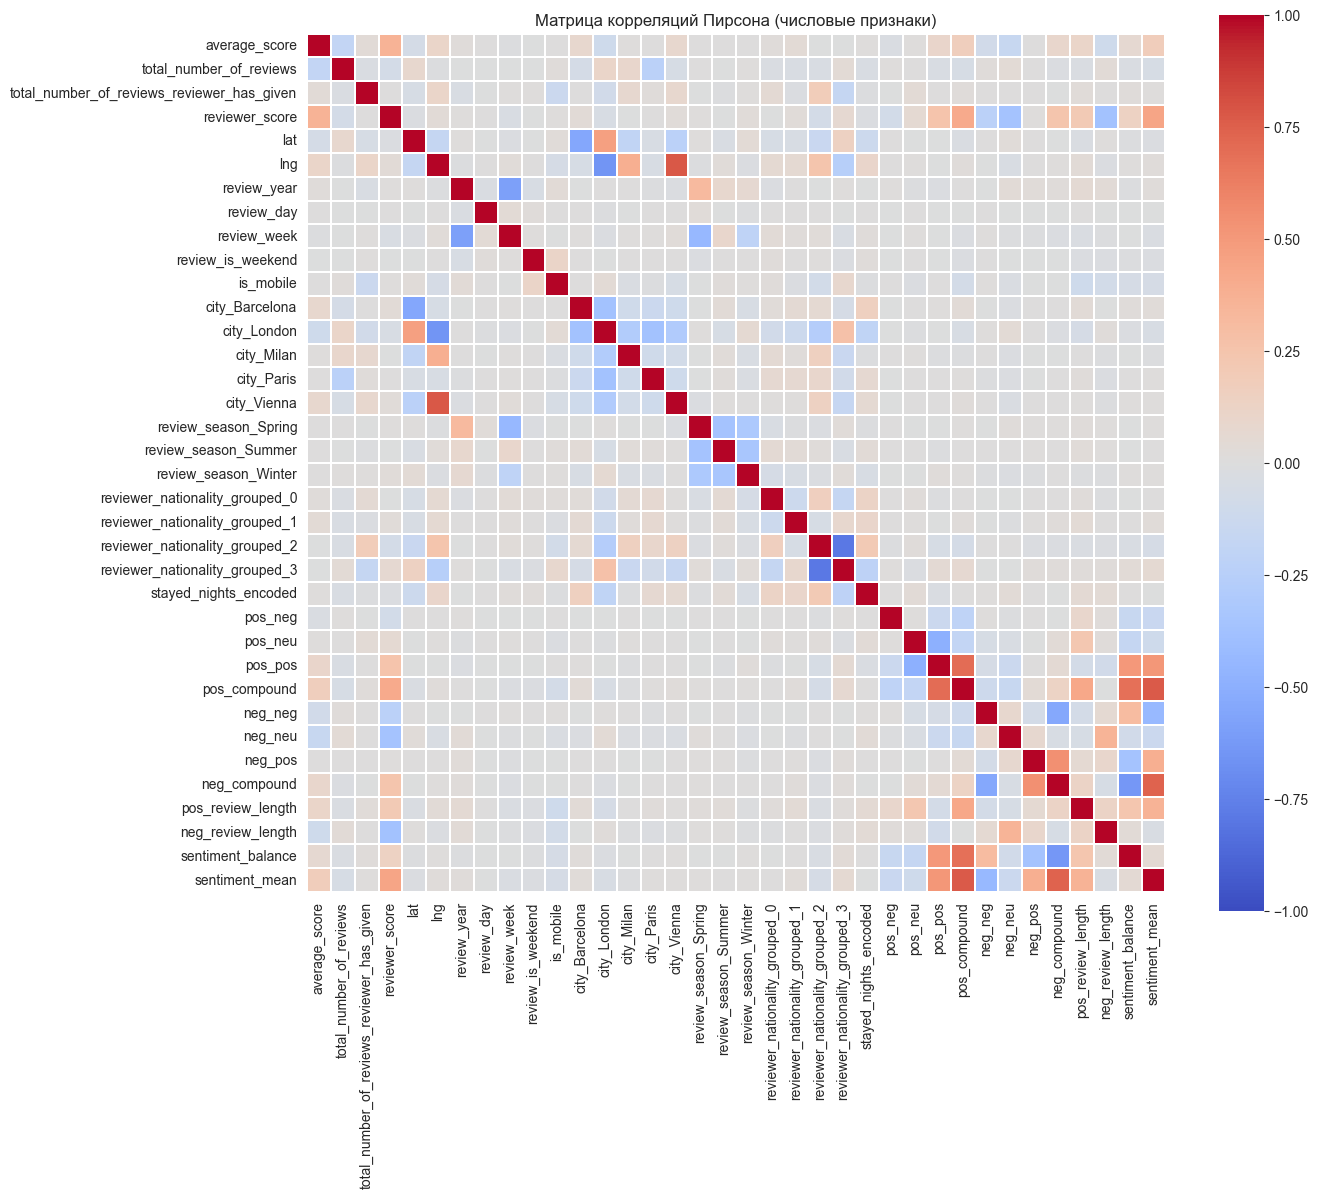


Пары с |corr| >= 0.8:
Empty DataFrame
Columns: [feature_1, feature_2, corr, abs_corr]
Index: []

Кандидаты на удаление из-за мультиколлинеарности:
[]


In [15]:
# отбираем числовые признаки
num_df = hotels_encoded.select_dtypes(include=[np.number])
print("Числовые признаки:", num_df.shape[1])

# матрица корреляций Пирсона
corr_matrix = num_df.corr(method='pearson', numeric_only=True)

# тепловая карта
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=False, 
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.3
)
plt.title("Матрица корреляций Пирсона (числовые признаки)")
plt.tight_layout()
plt.show()

# поиск сильно коррелирующих пар, берём верхний треугольник, чтобы не дублировать пары (a,b)/(b,a)
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'feature_1',
                     'level_1': 'feature_2',
                     0: 'corr'})
)
pairs['abs_corr'] = pairs['corr'].abs()
pairs = pairs.sort_values('abs_corr', ascending=False)

THRESHOLD = 0.8
high_corr = pairs[pairs['abs_corr'] >= THRESHOLD]
print(f"\nПары с |corr| >= {THRESHOLD}:")
print(high_corr.head(20).to_string(index=False))

# для каждой сильно коррелирующей пары удаляем один из признаков
to_drop = set()
for _, row in high_corr.iterrows():
    f1, f2 = row['feature_1'], row['feature_2']
    if f1 in to_drop or f2 in to_drop:
        continue
    # удалим тот, у кого больше средняя
    mean1 = corr_matrix[f1].abs().drop(f1).mean()
    mean2 = corr_matrix[f2].abs().drop(f2).mean()
    drop = f1 if mean1 >= mean2 else f2
    to_drop.add(drop)

print("\nКандидаты на удаление из-за мультиколлинеарности:")
print(sorted(to_drop))

# удаляем лишние признаки
hotels_encoded = hotels_encoded.drop(columns=list(to_drop))

## 5.2 Анализ мультиколлинеарности категориальных  признаков. 
Использование метода Спирмана


Пары (порядковые) с |rho| >= 0.7:
      feature_1       feature_2      corr  abs_corr
0  pos_compound  sentiment_mean  0.765829  0.765829

Кандидаты на удаление (Спирмен): ['sentiment_mean']


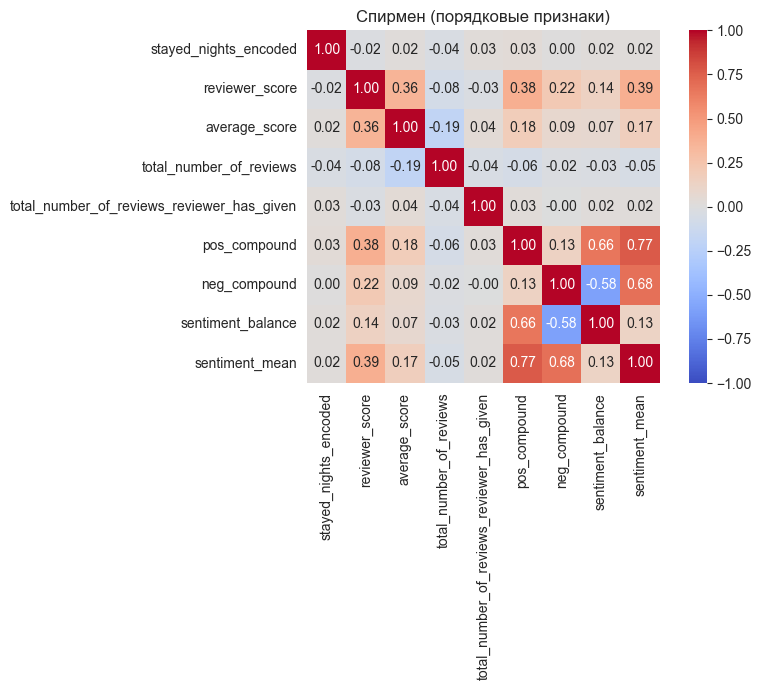

In [16]:
# отбираем признаки

ordinal_cols = [
    'stayed_nights_encoded',
    'reviewer_score',
    'average_score',
    'additional_number_of_scoring',
    'total_number_of_reviews',
    'review_total_negative_word_counts',
    'review_total_positive_word_counts',
    'total_number_of_reviews_reviewer_has_given',
    'pos_compound', 'neg_compound',
    'sentiment_balance', 'sentiment_mean',
]

ordinal_cols = [c for c in ordinal_cols if c in hotels_encoded.columns]

ordinal_df = hotels_encoded[ordinal_cols].apply(
    pd.to_numeric, errors='coerce'
)

# матрица корреляций Спирмена
corr_spearman = ordinal_df.corr(method='spearman')

# поиск сильно коррелирующих пар в верхнем сегменте
upper = corr_spearman.where(
    np.triu(np.ones(corr_spearman.shape), k=1).astype(bool)
)

threshold = 0.7

high_corr = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'feature_1',
                     'level_1': 'feature_2',
                     0: 'corr'})
)
high_corr['abs_corr'] = high_corr['corr'].abs()
high_corr = (
    high_corr[high_corr['abs_corr'] >= threshold]
    .sort_values('abs_corr', ascending=False)
    .reset_index(drop=True)
)

print(f"\nПары (порядковые) с |rho| >= {threshold}:")
print(high_corr)

# кандидаты на удаление
to_drop_spearman = set(high_corr['feature_2'])
print("\nКандидаты на удаление (Спирмен):", sorted(to_drop_spearman))

# визуализация
try:
    import matplotlib.pyplot as plt
    import seaborn as sns

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corr_spearman, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, ax=ax)
    ax.set_title('Спирмен (порядковые признаки)')
    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib/seaborn не установлены — пропускаем график")
    
to_drop_spearman = set(to_drop_spearman)

# 6. Отбор признаков на основе их важности.

## 6.1. Проводим тест ANOVA

Гипотезы:
* H₀: средние reviewer_score одинаковы во всех городах
* H₁: хотя бы в одном городе средняя оценка отличается

In [17]:
from scipy import stats

# восстанавливаем город из one-hot колонок
city_cols = ["city_Barcelona", "city_London", "city_Milan", "city_Paris", "city_Vienna"]
hotels_encoded["city"] = hotels_encoded[city_cols].idxmax(axis=1).str.replace("city_", "")

# задаём уровень значимости
alpha = 0.05 
print("Уровень значимости alpha = {:.2f}".format(alpha))

groups = [g["reviewer_score"].values for _, g in hotels_encoded.groupby("city")]
F, p = stats.f_oneway(*groups)
print(f"F = {F:.3f}, p = {p:.4f}")

# функция для принятия решения об отклонении нулевой гипотезы
def decision_hypothesis(p):
    print('p-value = {:.3f}'.format(p))
    if p <= alpha:
        print('p-значение меньше, чем заданный уровень значимости {:.2f}. Отвергаем нулевую гипотезу в пользу альтернативной.'.format(alpha))
    else:
        print('p-значение больше, чем заданный уровень значимости {:.2f}. У нас нет оснований отвергнуть нулевую гипотезу.'.format(alpha))
        
decision_hypothesis(p)

Уровень значимости alpha = 0.05
F = 255.896, p = 0.0000
p-value = 0.000
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу в пользу альтернативной.


Вывод: Средние оценки по городам различаются

## 6.2. Тест хи-квадрат (χ²)

### 6.2.1 Связь типа поездки и оценки
Гипотезы
* H₀: Тип поездки и оценка независимы: доля высоких/низких оценок одинакова для всех типов поездок
* H₁: Тип поездки связан с оценкой: распределение оценок различается между типами поездок

In [18]:
import scipy.stats as stats
import pandas as pd

# задаём уровень значимости
alpha = 0.05 

# вычисляем таблицу сопряжённости
table = pd.crosstab(hotels_encoded['trip_type'], hotels_encoded['score_bucket'])

# проводим тест
_, p, _, _ = stats.chi2_contingency(table)

print('p-value = {:.3f}'.format(p))

# интерпретируем результат
if p <= alpha:
    print('p-значение меньше, чем заданный уровень значимости {:.2f}. Отвергаем нулевую гипотезу.'.format(alpha))
else:
    print('p-значение больше, чем заданный уровень значимости {:.2f}. У нас нет оснований отвергнуть нулевую гипотезу.'.format(alpha))

p-value = 0.000
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу.


### 6.2.2 Связь выходного дня и оценки
Гипотезы
* H₀: Признак выходного дня и оценка независимы
* H₁: Выходной день связан с оценкой

In [19]:
import scipy.stats as stats
import pandas as pd

# задаём уровень значимости
alpha = 0.05 

# вычисляем таблицу сопряжённости
table = pd.crosstab(hotels_encoded['review_is_weekend'], hotels_encoded['score_bucket'])

# проводим тест
_, p, _, _ = stats.chi2_contingency(table)

print('p-value = {:.3f}'.format(p))

# интерпретируем результат
if p <= alpha:
    print('p-значение меньше, чем заданный уровень значимости {:.2f}. Отвергаем нулевую гипотезу.'.format(alpha))
else:
    print('p-значение больше, чем заданный уровень значимости {:.2f}. У нас нет оснований отвергнуть нулевую гипотезу.'.format(alpha))

p-value = 0.002
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу.


### 6.2.3 Связь категории номера и оценки
Гипотезы
* H₀: Категория номера и оценка независимы
* H₁: Категория номера связана с оценкой

In [20]:
import scipy.stats as stats
import pandas as pd

# задаём уровень значимости
alpha = 0.05 

# вычисляем таблицу сопряжённости
table = pd.crosstab(hotels_encoded['room_type'], hotels_encoded['score_bucket'])

# проводим тест
_, p, _, _ = stats.chi2_contingency(table)

print('p-value = {:.3f}'.format(p))

# интерпретируем результат
if p <= alpha:
    print('p-значение меньше, чем заданный уровень значимости {:.2f}. Отвергаем нулевую гипотезу.'.format(alpha))
else:
    print('p-значение больше, чем заданный уровень значимости {:.2f}. У нас нет оснований отвергнуть нулевую гипотезу.'.format(alpha))

p-value = 0.000
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу.


### 6.2.4 Связь типа путешественника и оценки
Гипотезы
* H₀: Тип путешественника и оценка независимы
* H₁: Тип путешественника связан с оценкой

In [21]:
import scipy.stats as stats
import pandas as pd

# задаём уровень значимости
alpha = 0.05 

# вычисляем таблицу сопряжённости
table = pd.crosstab(hotels_encoded['traveler_type'], hotels_encoded['score_bucket'])

# проводим тест
_, p, _, _ = stats.chi2_contingency(table)

print('p-value = {:.3f}'.format(p))

# интерпретируем результат
if p <= alpha:
    print('p-значение меньше, чем заданный уровень значимости {:.2f}. Отвергаем нулевую гипотезу.'.format(alpha))
else:
    print('p-значение больше, чем заданный уровень значимости {:.2f}. У нас нет оснований отвергнуть нулевую гипотезу.'.format(alpha))

p-value = 0.000
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу.


### 6.2.5 Связь сезонности и оценки
Гипотезы
* H₀: Месяц отзыва и бакет оценки независимы
* H₁: Месяц отзыва связан с оценкой

In [22]:
import scipy.stats as stats
import pandas as pd

# задаём уровень значимости
alpha = 0.05 

# вычисляем таблицу сопряжённости
table = pd.crosstab(hotels_encoded['review_month_name'], hotels_encoded['score_bucket'])

# проводим тест
_, p, _, _ = stats.chi2_contingency(table)

print('p-value = {:.3f}'.format(p))

# интерпретируем результат
if p <= alpha:
    print('p-значение меньше, чем заданный уровень значимости {:.2f}. Отвергаем нулевую гипотезу.'.format(alpha))
else:
    print('p-значение больше, чем заданный уровень значимости {:.2f}. У нас нет оснований отвергнуть нулевую гипотезу.'.format(alpha))

p-value = 0.000
p-значение меньше, чем заданный уровень значимости 0.05. Отвергаем нулевую гипотезу.


# 7. Реализация машинного алгоритма и проверка его эффективности.

## 7.1 Удаляем лишние признаки

In [23]:
# Определить текстовые (объектные/строковые) столбцы
text_cols = hotels_encoded.select_dtypes(include=['object']).columns.tolist()
print("Text columns to remove:", text_cols)

# Удалить текстовые столбцы
df_numeric = hotels_encoded.drop(columns=text_cols)

print("\nОставшиеся столбцы:")
print(df_numeric.columns.tolist())


cols_to_drop = hotels_encoded.select_dtypes(include=['object']).columns

hotels_encoded = hotels_encoded.drop(columns=cols_to_drop)

hotels_encoded = hotels_encoded.select_dtypes(exclude=['category'])

datetime_cols = hotels_encoded.select_dtypes(include=['datetime', 'datetimetz']).columns
print('Удаляем колонки:', list(datetime_cols))
hotels_encoded = hotels_encoded.drop(datetime_cols, axis=1)
display(hotels_encoded.head())
display(hotels_encoded.info())

Text columns to remove: ['hotel_address', 'hotel_name', 'reviewer_nationality', 'negative_review', 'positive_review', 'tags', 'days_since_review', 'country', 'review_day_name', 'review_month_name', 'reviewer_nationality_grouped', 'city']

Оставшиеся столбцы:
['review_date', 'average_score', 'total_number_of_reviews', 'total_number_of_reviews_reviewer_has_given', 'reviewer_score', 'lat', 'lng', 'review_year', 'review_day', 'review_week', 'review_is_weekend', 'trip_type', 'traveler_type', 'room_type', 'is_mobile', 'city_Barcelona', 'city_London', 'city_Milan', 'city_Paris', 'city_Vienna', 'review_season_Spring', 'review_season_Summer', 'review_season_Winter', 'reviewer_nationality_grouped_0', 'reviewer_nationality_grouped_1', 'reviewer_nationality_grouped_2', 'reviewer_nationality_grouped_3', 'stayed_nights_encoded', 'pos_neg', 'pos_neu', 'pos_pos', 'pos_compound', 'neg_neg', 'neg_neu', 'neg_pos', 'neg_compound', 'pos_review_length', 'neg_review_length', 'sentiment_balance', 'sentiment_m

,average_score,total_number_of_reviews,total_number_of_reviews_reviewer_has_given,reviewer_score,lat,lng,review_year,review_day,review_week,review_is_weekend,...,pos_pos,pos_compound,neg_neg,neg_neu,neg_pos,neg_compound,pos_review_length,neg_review_length,sentiment_balance,sentiment_mean
0,8.4,1994,7,10.0,51.507894,-0.143671,2016,19,7,0,...,0.655,0.5859,0.000,1.000,0.0,0.0000,3.0,1.0,0.5859,0.29295
1,8.3,1361,14,6.3,51.521009,-0.123097,2017,12,2,0,...,0.000,0.0000,0.756,0.244,0.0,-0.4767,1.0,2.0,0.4767,-0.23835
2,8.9,406,14,7.5,48.845377,2.325643,2016,18,42,0,...,0.000,0.0000,0.423,0.577,0.0,-0.2960,2.0,4.0,0.2960,-0.14800
3,7.5,607,8,10.0,48.888697,2.394540,2015,22,39,0,...,0.721,0.9169,0.000,0.000,0.0,0.0000,9.0,2.0,0.9169,0.45845
4,8.5,7586,10,9.6,52.385601,4.847060,2016,5,9,1,...,0.382,0.8503,0.667,0.333,0.0,-0.2500,18.0,2.0,1.1003,0.30015


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 386803 entries, 0 to 386802
Data columns (total 36 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   average_score                               386803 non-null  float64
 1   total_number_of_reviews                     386803 non-null  int64  
 2   total_number_of_reviews_reviewer_has_given  386803 non-null  int64  
 3   reviewer_score                              386803 non-null  float64
 4   lat                                         386803 non-null  float64
 5   lng                                         386803 non-null  float64
 6   review_year                                 386803 non-null  int32  
 7   review_day                                  386803 non-null  int32  
 8   review_week                                 386803 non-null  int64  
 9   review_is_weekend                           386803 non-null  int64  
 

None

## 7.2 Реализация машинного алгоритма
Разбивка на тестовый и обучающий фрагменты, обучаем модель, оцениваем результат


In [24]:
# Разбиваем датафрейм на части, необходимые для обучения и тестирования модели
# X — данные с информацией об отелях, y — целевая переменная (рейтинги отелей)
X = hotels_encoded.drop(['reviewer_score'], axis=1)
y = hotels_encoded['reviewer_score']

# Загружаем специальный инструмент для разбивки:
from sklearn.model_selection import train_test_split

# Наборы данных с меткой "train" будут использоваться для обучения модели, "test" — для тестирования.
# Для тестирования мы будем использовать 25 % от исходного датасета.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Импортируем необходимые библиотеки:
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

# Создаём модель
regr = RandomForestRegressor(n_estimators=100)

# Обучаем модель на тренировочном наборе данных
regr.fit(X_train, y_train)

# Используем обученную модель для предсказания рейтинга отелей в тестовой выборке.
y_pred = regr.predict(X_test)

# Сравниваем предсказанные значения с реальными
print('MAPE:', metrics.mean_absolute_percentage_error(y_test, y_pred))

MAPE: 0.12383161246425707
